<div style="background: linear-gradient(135deg, #1e50a0 0%, #2e6cc0 100%); padding: 36px 40px; border-radius: 10px; color: white; margin-bottom: 20px;">
    <h1 style="color: white; margin: 0 0 8px 0; font-size: 2em;">Introduction to PINNs | Dynamics Case</h1>
    <h2 style="color: #c8dcff; margin: 0 0 12px 0; font-weight: normal; font-size: 1.3em;">Duffing Oscillator: Inverse PINN for Parameter Identification</h2>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Inverse PINN &nbsp;·&nbsp; Learnable physical parameters &nbsp;·&nbsp; Initial conditions + physics + noisy data &nbsp;·&nbsp; Normalisation &nbsp;·&nbsp; PyTorch</p>
    <hr>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Author: A.S.Grm (aleksander.grm@fpp.uni-lj.si), 2026</p>
</div>

### Problem summary

A forced mass–spring–damper with a cubic (hardening) spring, the **Duffing oscillator**:

$$m\ddot x + c\dot x + kx + \alpha x^3 = F\cos(\Omega t), \qquad x(0)=x_0,\ \ \dot x(0)=v_0,\qquad t\in[0,30]\ \text{s}.$$

| Parameter | Symbol | Value |
|---|---|---|
| mass | $m$ | 1.0 kg |
| linear stiffness | $k$ | 1.0 N/m |
| damping | $c$ | 0.75 N·s/m |
| cubic stiffness | $\alpha$ | 1.0 N/m³ (**unknown, to be identified**) |
| forcing amplitude / frequency | $F,\ \Omega$ | 0.5 N, 1.0 rad/s |
| initial state | $x_0,\ v_0$ | 0.1 m, 0 m/s |

**Inverse PINN.** The unknown $\alpha$ is declared as a trainable scalar $\hat\alpha$ (a `torch.nn.Parameter`) and
optimised **together with** the network weights. Optionally the damping $c$ can be identified as well (`identify_c=True`).
The network $\tilde t\mapsto\tilde x$ (normalised in and out) is trained with

$$\mathcal L = \lambda_\text{IC}\,\Big[(\hat x(0)-x_0)^2+(\dot{\hat x}(0)-v_0)^2\Big]
+ \lambda_\text{phys}\,\frac{1}{N_f}\sum_i r_i^2
+ \lambda_\text{data}\,\frac{1}{N_d}\sum_j\big(\tilde{\hat x}(\tilde t_j)-\tilde x^\text{exp}_j\big)^2,$$

$$r_i = m\ddot{\hat x}_i + \hat c\,\dot{\hat x}_i + k\hat x_i + \hat\alpha\,\hat x_i^3 - F\cos(\Omega t_i).$$

The gradient $\partial\mathcal L_\text{phys}/\partial\hat\alpha = \frac{2}{N_f}\sum_i r_i\,\hat x_i^3$ tells the optimiser how to move $\hat\alpha$.
Without data ($\lambda_\text{data}=0$) the problem is ill-posed: for *any* $\hat\alpha$ there is a trajectory satisfying the ODE and the IC,
so the **measurements are what pins down the parameter**.

Validation: displacement against a high-accuracy reference (`scipy.integrate.solve_ivp`, DOP853) and $\hat\alpha$ against the true value.

| Code cell | Content |
|---|---|
| 1–2 | imports, compute device |
| 3–5 | physical parameters, reference solution, synthetic noisy measurements |
| 6–7 | normaliser, neural network |
| 8–9 | learnable physical parameters, ODE residual (autograd) |
| 10–11 | collocation points, training loop |
| 12–13 | experiment driver with validation metrics, results dashboard |
| 14–15 | `main()` and entry point |

**Practical notes**
- *Separate learning rate for the parameters* (`lr_params = 1e-2`, network `lr = 1e-3`): with a single learning rate the scalar
  $\hat\alpha$ creeps towards its O(1) value very slowly; that is why the original worksheet needed 30 000 epochs.
- *Early oscillation of $\hat\alpha$*: while the network still fits the data poorly, the residual is dominated by fitting errors and $\hat\alpha$ may swing
  (even negative). It settles once $\mathcal L_\text{data}$ drops; this is normal.
- *Noise floor*: the data loss cannot fall below about $(\sigma_\text{noise}/\sigma_x)^2$ (here $\approx(0.01/0.42)^2\approx 6\cdot10^{-4}$).
  A data loss far below this value means the network is fitting the noise.
- *Experiments*: `alpha_init = 5.0` (far initial guess), `identify_c = True` (two unknowns), fewer points `N_data = 20`, larger `noise_std`,
  or `lambda_data = 0.0` (no data: $\hat\alpha$ is no longer identifiable).

In [1]:
import time
import platform
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from tqdm.auto import tqdm

In [2]:
# Prefer GPU (CUDA / AMD ROCm / Apple Silicon); fall back to CPU when no GPU is detected.
# dd = None  -> automatic selection
# dd = 'cpu' | 'cuda' | 'mps' -> force a specific device
def get_device(dd=None):

    if dd is None:
        if torch.cuda.is_available():
            device = torch.device("cuda")
            device_name = torch.cuda.get_device_name(0)
        elif torch.backends.mps.is_available():
            device = torch.device("mps")
            device_name = f"Apple Silicon ({platform.processor()})"
        else:
            device = torch.device("cpu")
            device_name = "GPU not detected – training will be slower"
    else:
        if dd == "cuda":
            device = torch.device("cuda")
            device_name = torch.cuda.get_device_name(0)
        elif dd == "mps":
            device = torch.device("mps")
            device_name = f"Apple Silicon ({platform.processor()})"
        elif dd == "cpu":
            device = torch.device("cpu")
            device_name = "CPU (forced)"
        else:
            raise ValueError(f"Device name is not supported: {dd}")

    print(f"Compute device : {device} ({device_name})")

    return device

In [3]:
# All physical constants in ONE object: every function receives 'p' explicitly.
# The values below are the TRUE values; they are used to generate the synthetic
# measurements and for validation. The PINN never sees p.alpha (nor p.c when
# identify_c=True) – it must discover them from the data.
@dataclass
class DuffingParams:

    m:     float = 1.0     # mass [kg]
    k:     float = 1.0     # linear stiffness [N/m]
    c:     float = 0.75    # viscous damping [N s/m]
    alpha: float = 1.0     # cubic stiffness [N/m^3]  <- the unknown
    F:     float = 0.5     # forcing amplitude [N]
    Omega: float = 1.0     # forcing angular frequency [rad/s]

    # Initial state at t = 0
    x0: float = 0.1        # displacement [m]
    v0: float = 0.0        # velocity [m/s]

    # Time window [s] – long enough to contain the transient AND several
    # steady-state periods (2*pi/Omega ≈ 6.3 s), where the amplitude is largest
    # and the cubic term alpha*x^3 has the most influence.
    t_start: float = 0.0
    t_end:   float = 30.0

    @property
    def initial_state(self):
        return [self.x0, self.v0]

In [4]:
def duffing_rhs(t, state, p):
    """
    Duffing equation as a FIRST-ORDER system  ds/dt = F(t, s),  s = [x, v]:
        x' = v
        v' = (F cos(Omega t) - c v - k x - alpha x^3) / m

    Parameters
    ----------
    t : float          time [s] (the system is forced, so t appears explicitly)
    state : array_like [x, v]
    p : DuffingParams

    Returns
    -------
    list of float : [x', v']
    """
    x, v = state
    a = (p.F * np.cos(p.Omega * t) - p.c * v - p.k * x - p.alpha * x**3) / p.m
    return [v, a]


def solve_reference(p, t_eval):
    """
    High-accuracy reference solution (8th-order Runge–Kutta DOP853, tight
    tolerances), used for synthetic measurements and validation.

    Returns
    -------
    sol : np.ndarray, shape (len(t_eval), 2)   columns: x [m], v [m/s]
    """
    out = solve_ivp(
        fun=duffing_rhs,
        t_span=(p.t_start, p.t_end),
        y0=p.initial_state,
        t_eval=t_eval,
        args=(p,),             # extra arguments forwarded to duffing_rhs
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )
    if not out.success:
        raise RuntimeError(f"Reference ODE solver failed: {out.message}")

    # solve_ivp returns (2, N); transpose to (N, 2) = one row per time instant
    return out.y.T

In [5]:
def generate_experimental_data(p, N_data, noise_std, seed):
    """
    Synthetic "displacement sensor": x(t) sampled at random instants and
    corrupted by zero-mean Gaussian noise. Velocity is NOT measured.

    Returns
    -------
    t_data : np.ndarray, shape (N_data,)   sorted measurement times [s]
    x_data : np.ndarray, shape (N_data,)   noisy displacements [m]
    """
    # Independent, reproducible random generator
    rng = np.random.default_rng(seed)

    t_data = np.sort(rng.uniform(p.t_start, p.t_end, N_data))
    x_exact = solve_reference(p, t_data)[:, 0]
    x_data = x_exact + noise_std * rng.standard_normal(N_data)

    return t_data, x_data

In [6]:
# Normalisation keeps the network's input and output of order one:
#   time t in [0, 30] s  -> t~ in [-1, 1]
#   displacement x [m]   -> x~ with zero mean and unit standard deviation
# The statistics come from the MEASURED data only (the true solution is unknown).
class Normaliser:

    def __init__(self, t_min, t_max, x_data):
        self.t_min = float(t_min)
        self.t_max = float(t_max)
        self.mu    = float(np.mean(x_data))
        self.sigma = float(np.std(x_data))

    # Physical time t [s]  ->  normalised time t~ in [-1, 1]
    def normalise_t(self, t):
        return 2.0 * (t - self.t_min) / (self.t_max - self.t_min) - 1.0

    # Physical displacement [m]  ->  normalised displacement
    def normalise_x(self, x):
        return (x - self.mu) / self.sigma

    # Normalised network output  ->  physical displacement [m]
    def denormalise_x(self, x_norm):
        return x_norm * self.sigma + self.mu

In [7]:
# Fully connected network: 1 input (t~) -> num_layers x hidden_dim tanh -> 1 output (x~).
class PINN1DOF(nn.Module):

    def __init__(self, hidden_dim, num_layers):

        # Required call: initialises PyTorch's internal parameter bookkeeping.
        super().__init__()

        # tanh is smooth (infinitely differentiable): the residual needs the SECOND
        # time derivative of the output, which is identically zero for ReLU.
        layers = [nn.Linear(1, hidden_dim), nn.Tanh()]
        for _ in range(num_layers - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.Tanh()]

        # Linear output layer: the displacement is an unbounded real number.
        layers.append(nn.Linear(hidden_dim, 1))

        self.net = nn.Sequential(*layers)

        # Xavier (Glorot) initialisation keeps the signal variance roughly
        # constant through tanh layers -> better-behaved early training.
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, t_norm):
        return self.net(t_norm)

In [8]:
# THE NEW INGREDIENT OF AN INVERSE PINN: unknown physical constants become
# trainable tensors. Wrapping them in an nn.Module lets us store them neatly,
# move them to the device with .to(device) and hand them to the optimiser.
class LearnableParams(nn.Module):

    def __init__(self, p, alpha_init, identify_c, c_init):

        super().__init__()

        # nn.Parameter = tensor with requires_grad=True that is registered as a
        # trainable parameter: autograd computes d(loss)/d(alpha_hat) and the
        # optimiser updates it at every step – exactly like a network weight.
        self.alpha = nn.Parameter(torch.tensor([float(alpha_init)]))

        # Optional second unknown: damping. If not identified, the known value
        # is stored as a BUFFER (moves with .to(device) but is NOT trained).
        self.identify_c = identify_c
        if identify_c:
            self.c = nn.Parameter(torch.tensor([float(c_init)]))
        else:
            self.register_buffer("c", torch.tensor([float(p.c)]))

    def as_dict(self):
        """Current values as Python floats (for logging and plotting)."""
        return {"alpha": self.alpha.item(), "c": self.c.item()}

In [9]:
def predict_x(model, t, norm):
    """
    Full prediction chain in PHYSICAL units:
        t [s] --normalise--> t~ --network--> x~ --denormalise--> x [m]
    Autograd differentiates through the (de)normalisation, so derivatives taken
    w.r.t. 't' are directly in m/s and m/s^2 (chain-rule factors included).
    """
    return norm.denormalise_x(model(norm.normalise_t(t)))


def d_dt(y, t):
    """
    Pointwise derivative dy/dt of a column tensor y(t), shape (N, 1).
    grad_outputs = ones -> pointwise derivative (each y_i depends only on t_i).
    create_graph = True -> result stays differentiable (needed for the second
    derivative and for back-propagating the loss to weights AND parameters).
    """
    return torch.autograd.grad(y, t, grad_outputs=torch.ones_like(y), create_graph=True)[0]


def compute_ode_residual(model, t, norm, p, learn):
    """
    Duffing residual  r = m x'' + c_hat x' + k x + alpha_hat x^3 - F cos(Omega t)
    at the collocation times t (shape (N, 1), requires_grad=True).

    The known constants (m, k, F, Omega) come from p; the unknown ones
    (alpha_hat and optionally c_hat) come from the trainable object 'learn'.
    Because alpha_hat enters the residual, d(L_phys)/d(alpha_hat) is non-zero
    and the optimiser can update it.
    """
    x   = predict_x(model, t, norm)    # displacement [m]
    dx  = d_dt(x, t)                   # velocity [m/s]
    d2x = d_dt(dx, t)                  # acceleration [m/s^2]

    r = (p.m * d2x
         + learn.c * dx
         + p.k * x
         + learn.alpha * x**3                       # <- unknown cubic stiffness
         - p.F * torch.cos(p.Omega * t))
    return r

In [10]:
def generate_domain_points(t_start, t_end, N_f, device):
    """
    Returns
    -------
    t_f  : (N_f, 1) collocation times for the physics residual (requires_grad)
    t_ic : (1, 1)   the initial time; requires_grad because the initial
                    VELOCITY dx/dt(0) is part of the IC loss
    """
    t_f = torch.linspace(t_start, t_end, N_f, device=device).unsqueeze(1)
    t_f.requires_grad_(True)
    t_ic = torch.tensor([[t_start]], device=device, requires_grad=True)
    return t_f, t_ic

In [11]:
def train_pinn(
    model,
    learn,
    norm,
    p,
    t_f,
    t_ic,
    t_data,
    x_data,
    epochs,
    lr,
    lr_params,
    lambda_ic,
    lambda_phys,
    lambda_data,
    print_every,
):
    """
    Jointly trains the network weights AND the unknown physical parameters.

    lr        : learning rate of the network weights
    lr_params : learning rate of the physical parameters. A separate (larger)
                value is useful: a single scalar with an O(1) target value moves
                very slowly with lr = 1e-3, which is the main reason inverse
                PINNs "need" so many epochs.
    lambda_*  : weights of the IC, physics and data losses

    Returns
    -------
    history : dict of per-epoch lists: losses, lr, alpha, c
    """
    # Two PARAMETER GROUPS in ONE Adam optimiser: same algorithm, different step sizes.
    optimizer = torch.optim.Adam([
        {"params": model.parameters(), "lr": lr},
        {"params": [q for q in learn.parameters()], "lr": lr_params},
    ])

    # Halve both learning rates four times during training (staircase decay).
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=max(1, epochs // 4), gamma=0.5
    )

    # Data loss in NORMALISED space; targets are fixed -> precompute.
    t_data_norm = norm.normalise_t(t_data)
    x_data_norm = norm.normalise_x(x_data)

    history = {"total": [], "ic": [], "phys": [], "data": [], "lr": [], "alpha": [], "c": []}

    for epoch in tqdm(range(epochs + 1), desc="Training", unit="epoch", mininterval=1.0):

        # PyTorch accumulates gradients -> reset them every step.
        optimizer.zero_grad()

        # ---------------------------------------------------------------
        # TERM 1: initial conditions x(0) = x0, x'(0) = v0
        # ---------------------------------------------------------------
        x_ic = predict_x(model, t_ic, norm)
        v_ic = d_dt(x_ic, t_ic)
        loss_ic = torch.mean((x_ic - p.x0)**2) + torch.mean((v_ic - p.v0)**2)

        # ---------------------------------------------------------------
        # TERM 2: physics residual with the CURRENT estimates alpha_hat, c_hat
        # ---------------------------------------------------------------
        r = compute_ode_residual(model, t_f, norm, p, learn)
        loss_phys = torch.mean(r**2)

        # ---------------------------------------------------------------
        # TERM 3: noisy displacement measurements (normalised space)
        # ---------------------------------------------------------------
        loss_data = torch.mean((model(t_data_norm) - x_data_norm)**2)

        # ---------------------------------------------------------------
        # TOTAL loss, backward pass (gradients for weights AND parameters), step
        # ---------------------------------------------------------------
        loss = lambda_ic * loss_ic + lambda_phys * loss_phys + lambda_data * loss_data
        loss.backward()
        optimizer.step()
        scheduler.step()

        # RECORD (the parameter trajectory is the signature plot of an inverse PINN)
        vals = learn.as_dict()
        history["total"].append(loss.item())
        history["ic"].append(loss_ic.item())
        history["phys"].append(loss_phys.item())
        history["data"].append(loss_data.item())
        history["lr"].append(optimizer.param_groups[0]["lr"])
        history["alpha"].append(vals["alpha"])
        history["c"].append(vals["c"])

        if epoch % print_every == 0:
            msg = (f"Epoch {epoch:6d} | Loss: {loss.item():.3e} | IC: {loss_ic.item():.3e} | "
                   f"Phys: {loss_phys.item():.3e} | Data: {loss_data.item():.3e} | "
                   f"alpha: {vals['alpha']:.4f}")
            if learn.identify_c:
                msg += f" | c: {vals['c']:.4f}"
            tqdm.write(msg)

    return history

In [12]:
def compute_pinn_experiment(
    p,
    hidden_dim,
    num_layers,
    N_f,
    N_data,
    noise_std,
    alpha_init,
    identify_c,
    c_init,
    epochs,
    lr,
    lr_params,
    lambda_ic,
    lambda_phys,
    lambda_data,
    seed,
    device,
):
    """
    Complete pipeline for ONE configuration:
      1. synthetic measurements      2. normaliser
      3. collocation points          4. network + learnable parameters + training
      5. validation: displacement vs reference, identified vs true parameters
    """
    # STEP 1: synthetic measurements (true parameters used ONLY here and in validation)
    t_data_np, x_data_np = generate_experimental_data(p, N_data, noise_std, seed)

    # STEP 2: normaliser from the measured data
    norm = Normaliser(p.t_start, p.t_end, x_data_np)
    t_data = torch.tensor(t_data_np, dtype=torch.float32, device=device).unsqueeze(1)
    x_data = torch.tensor(x_data_np, dtype=torch.float32, device=device).unsqueeze(1)

    # STEP 3: collocation points and initial time
    t_f, t_ic = generate_domain_points(p.t_start, p.t_end, N_f, device)

    # STEP 4: fresh network + unknown parameters, joint training
    torch.manual_seed(seed)
    model = PINN1DOF(hidden_dim, num_layers).to(device)
    learn = LearnableParams(p, alpha_init, identify_c, c_init).to(device)
    n_params = sum(q.numel() for q in model.parameters())
    unknowns = "alpha, c" if identify_c else "alpha"
    print(f"Network: 1 input -> {num_layers} x {hidden_dim} tanh -> 1 output ({n_params} weights)")
    print(f"Unknown physical parameters: {unknowns} | initial guess: {learn.as_dict()}")

    t0 = time.time()
    history = train_pinn(
        model, learn, norm, p, t_f, t_ic, t_data, x_data,
        epochs=epochs, lr=lr, lr_params=lr_params,
        lambda_ic=lambda_ic, lambda_phys=lambda_phys, lambda_data=lambda_data,
        print_every=max(1, epochs // 10),
    )
    print(f"Training time: {time.time() - t0:.1f} s")

    # STEP 5: validation on a fine grid independent of collocation/measurement points
    t_test_np = np.linspace(p.t_start, p.t_end, 1000)
    t_test = torch.tensor(t_test_np, dtype=torch.float32, device=device).unsqueeze(1)
    with torch.no_grad():
        x_pred = predict_x(model, t_test, norm).cpu().numpy().ravel()
    x_ref = solve_reference(p, t_test_np)[:, 0]

    abs_err = np.abs(x_pred - x_ref)
    rel_l2  = np.linalg.norm(x_pred - x_ref) / np.linalg.norm(x_ref)

    identified = learn.as_dict()
    print("\nValidation against reference solution (1000 test points):")
    print(f"  x(t): max |error| = {abs_err.max():.3e} m | "
          f"RMSE = {np.sqrt(np.mean(abs_err**2)):.3e} m | rel. L2 = {rel_l2:.3e}")
    print("Parameter identification:")
    print(f"  alpha: identified = {identified['alpha']:.4f} | true = {p.alpha:.4f} | "
          f"error = {100 * abs(identified['alpha'] - p.alpha) / abs(p.alpha):.2f} %")
    if identify_c:
        print(f"  c    : identified = {identified['c']:.4f} | true = {p.c:.4f} | "
              f"error = {100 * abs(identified['c'] - p.c) / abs(p.c):.2f} %")

    return {
        "model": model, "learn": learn, "history": history,
        "t_test": t_test_np, "x_pred": x_pred, "x_ref": x_ref,
        "t_data": t_data_np, "x_data": x_data_np,
        "abs_err": abs_err, "rel_l2": rel_l2,
        "identified": identified, "identify_c": identify_c,
    }

In [13]:
def plot_pinn_results(results, p, title):
    """
    2 x 2 dashboard:
      (a) x(t): PINN vs reference, with noisy measurements
      (b) parameter convergence (alpha_hat, and c_hat if identified)
      (c) training loss components (log scale)
      (d) absolute displacement error vs time (log scale)
    """
    t, hist = results["t_test"], results["history"]

    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    fig.suptitle(title, fontsize=14, fontweight="bold")

    # (a) displacement
    ax = axes[0, 0]
    ax.scatter(results["t_data"], results["x_data"], s=8, color="tab:blue", alpha=0.35,
               label="Noisy measurements")
    ax.plot(t, results["x_ref"], color="tab:blue", linewidth=2.5, alpha=0.6, label="Reference (DOP853)")
    ax.plot(t, results["x_pred"], "k--", linewidth=1.6, label="Inverse PINN")
    ax.scatter([p.t_start], [p.x0], color="tab:green", s=60, zorder=5, label="Initial condition")
    ax.set_title("(a) Displacement $x(t)$", fontsize=12, fontweight="bold")
    ax.set_xlabel("Time $t$ [s]")
    ax.set_ylabel("$x$ [m]")
    ax.legend(fontsize=9)
    ax.grid(True, linestyle=":", alpha=0.6)

    # (b) parameter convergence – the signature output of an inverse PINN
    ax = axes[0, 1]
    ax.plot(hist["alpha"], color="tab:red", linewidth=1.5,
            label=f"$\\hat\\alpha$ (final {results['identified']['alpha']:.4f})")
    ax.axhline(p.alpha, color="tab:red", linestyle=":", linewidth=1.5, label=f"true $\\alpha$ = {p.alpha}")
    if results["identify_c"]:
        ax.plot(hist["c"], color="tab:purple", linewidth=1.5,
                label=f"$\\hat c$ (final {results['identified']['c']:.4f})")
        ax.axhline(p.c, color="tab:purple", linestyle=":", linewidth=1.5, label=f"true $c$ = {p.c}")
    ax.set_title("(b) Parameter convergence", fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Parameter value")
    ax.legend(fontsize=9)
    ax.grid(True, linestyle=":", alpha=0.6)

    # (c) loss history
    ax = axes[1, 0]
    ax.semilogy(hist["total"], color="black", linewidth=1.4, label="Total")
    ax.semilogy(hist["phys"], color="tab:red", alpha=0.8, linewidth=1.0, label="Physics $\\mathcal{L}_{phys}$")
    ax.semilogy(hist["ic"], color="tab:green", alpha=0.8, linewidth=1.0, label="Initial cond. $\\mathcal{L}_{IC}$")
    ax.semilogy(hist["data"], color="tab:blue", alpha=0.8, linewidth=1.0, label="Data $\\mathcal{L}_{data}$")
    ax.set_title("(c) Training loss components", fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (log scale)")
    ax.legend(fontsize=9)
    ax.grid(True, which="both", linestyle=":", alpha=0.6)

    # (d) pointwise error
    ax = axes[1, 1]
    ax.semilogy(t, results["abs_err"], color="tab:blue", label="$|\\hat x - x_{ref}|$")
    ax.set_title(f"(d) Absolute error vs reference (rel. L2 = {results['rel_l2']:.2e})",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel("Time $t$ [s]")
    ax.set_ylabel("Absolute error [m]")
    ax.legend(fontsize=9)
    ax.grid(True, which="both", linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

In [14]:
def main(dd):
    """
    Main pipeline of the inverse Duffing PINN:
    device -> parameters & hyperparameters -> experiment -> dashboard.
    """
    print("=======================================================")
    print("   DUFFING OSCILLATOR – INVERSE PINN WORKFLOW")
    print("=======================================================\n")

    # STEP 1: device
    device = get_device(dd)

    # STEP 2: physical parameters (TRUE values) & hyperparameters
    p = DuffingParams()

    hidden_dim  = 64      # neurons per hidden layer
    num_layers  = 3       # hidden layers
    N_f         = 1000    # collocation points for the physics residual
    N_data      = 250     # noisy displacement measurements
    noise_std   = 0.01    # sensor noise standard deviation [m]

    alpha_init  = 0.0     # initial guess for alpha ("no cubic stiffness")
    identify_c  = False   # True -> identify damping c as a second unknown
    c_init      = 0.0     # initial guess for c (used only if identify_c=True)

    epochs      = 10000   # Adam iterations (both lr halved every epochs/4); ~4-5 min on CPU
    lr          = 1e-3    # learning rate of the network weights
    lr_params   = 1e-2    # learning rate of the physical parameters
    lambda_ic   = 1.0     # weight of the initial-condition loss
    lambda_phys = 1.0     # weight of the physics loss
    lambda_data = 1.0     # weight of the data loss (0.0 -> alpha is NOT identifiable)
    seed        = 123     # reproducibility of data and weight initialisation

    # STEP 3: run
    results = compute_pinn_experiment(
        p, hidden_dim, num_layers, N_f, N_data, noise_std,
        alpha_init, identify_c, c_init,
        epochs, lr, lr_params, lambda_ic, lambda_phys, lambda_data, seed, device,
    )

    # STEP 4: visualise
    plot_pinn_results(results, p, title="Duffing oscillator – inverse PINN (IC + physics + noisy data)")

    print("=======================================================")
    print("   PINN WORKFLOW SUCCESSFULLY COMPLETED!")
    print("=======================================================")

    return results

   DUFFING OSCILLATOR – INVERSE PINN WORKFLOW

Compute device : cuda (AMD Radeon RX 7600)
Network: 1 input -> 3 x 64 tanh -> 1 output (8513 weights)
Unknown physical parameters: alpha | initial guess: {'alpha': 0.0, 'c': 0.75}


Training:   0%|          | 0/10001 [00:00<?, ?epoch/s]

Epoch      0 | Loss: 1.165e+00 | IC: 1.740e-02 | Phys: 1.283e-01 | Data: 1.020e+00 | alpha: -0.0100
Epoch   1000 | Loss: 1.963e-02 | IC: 7.504e-04 | Phys: 1.448e-02 | Data: 4.402e-03 | alpha: 0.7640
Epoch   2000 | Loss: 1.209e-02 | IC: 9.727e-07 | Phys: 9.813e-03 | Data: 2.277e-03 | alpha: 0.7996
Epoch   3000 | Loss: 1.314e-03 | IC: 1.741e-06 | Phys: 7.062e-04 | Data: 6.063e-04 | alpha: 0.9826
Epoch   4000 | Loss: 5.866e-04 | IC: 8.386e-07 | Phys: 3.717e-05 | Data: 5.486e-04 | alpha: 1.0122
Epoch   5000 | Loss: 6.727e-04 | IC: 9.764e-06 | Phys: 5.636e-05 | Data: 6.066e-04 | alpha: 1.0109
Epoch   6000 | Loss: 5.671e-04 | IC: 3.590e-09 | Phys: 1.945e-05 | Data: 5.477e-04 | alpha: 1.0122
Epoch   7000 | Loss: 5.643e-04 | IC: 9.962e-09 | Phys: 1.663e-05 | Data: 5.477e-04 | alpha: 1.0121
Epoch   8000 | Loss: 5.628e-04 | IC: 7.220e-10 | Phys: 1.517e-05 | Data: 5.476e-04 | alpha: 1.0121
Epoch   9000 | Loss: 5.616e-04 | IC: 1.929e-09 | Phys: 1.409e-05 | Data: 5.475e-04 | alpha: 1.0121
Epoch  10

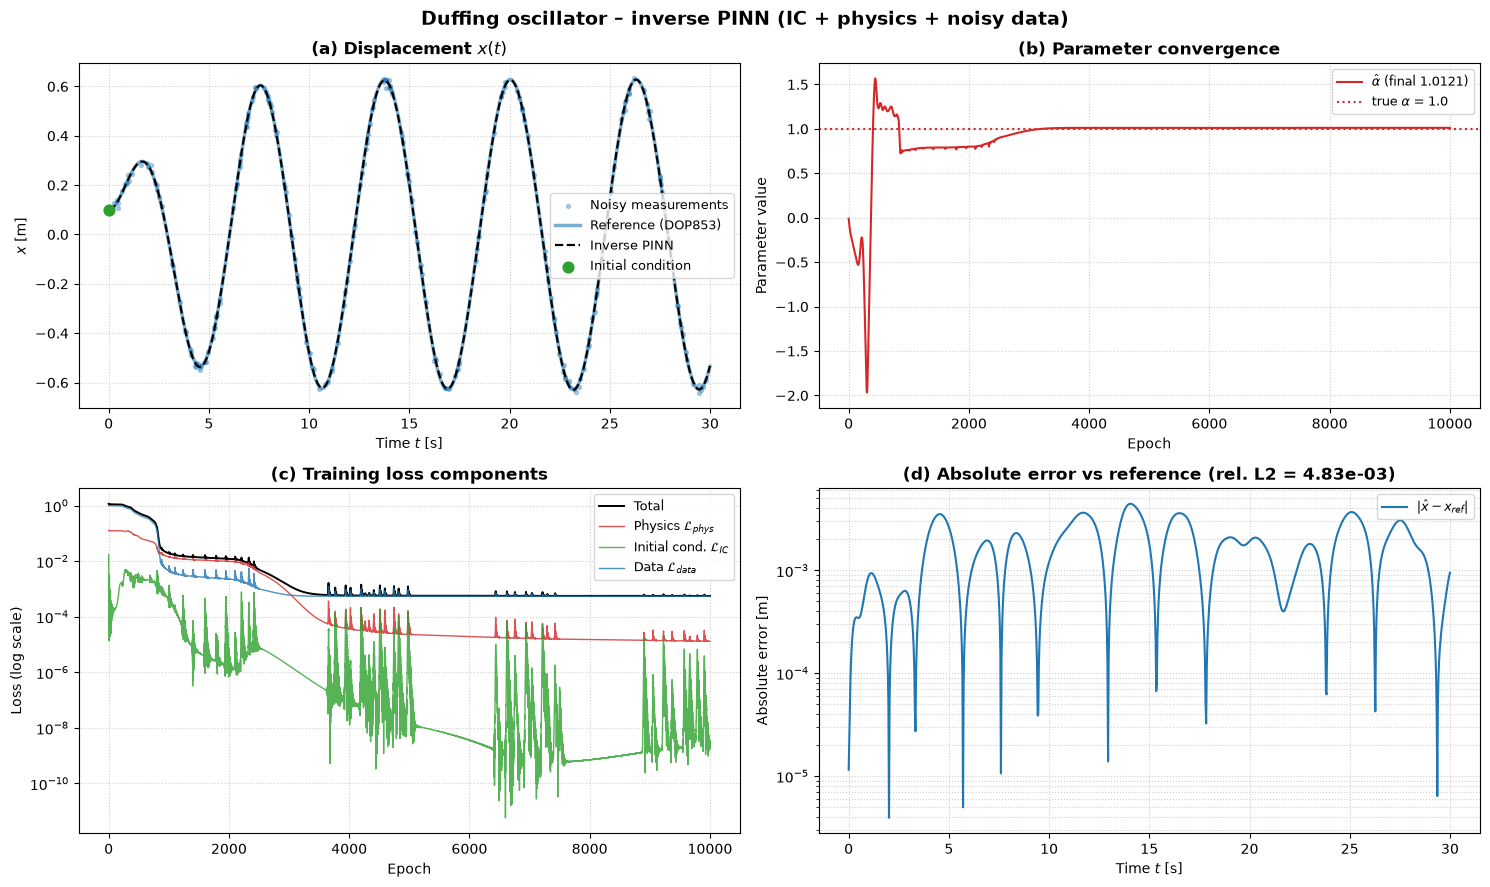

   PINN WORKFLOW SUCCESSFULLY COMPLETED!


In [15]:
# Standard Python entry point check: allows the code to be run as a script
# or imported as a module into another notebook.
if __name__ == "__main__":

    # Which device: CPU, Apple-Silicon GPU (MPS), CUDA GPU, or automatic (None).
    dd = ['cpu', 'mps', 'cuda', None]
    results = main(dd[3])